# Benchmark: the 0.9 quantile

A conditional quantile is a curve the response falls below with a fixed probability; the 0.9 quantile is the level a user plans for when 90% of outcomes must lie below it. This study asks whether `Quantile(tau=0.9)` recovers that curve as well as the exact minimiser of the check loss computed by linear programming, on a linear quantile and on a smooth one. The check (pinball) loss of a residual $u = y - q$ at level $\tau$ is $\rho_\tau(u) = u\,(\tau - \mathbf{1}\{u < 0\})$: residuals above the fit cost $\tau$ per unit and residuals below it $1 - \tau$, and its expected value is smallest at the true $\tau$-quantile.

The noise is Gaussian with a constant scale, so the 0.9 quantile is the mean shifted by `scale * Phi^{-1}(0.9)`, where $\Phi^{-1}(0.9) = 1.2816$ is the 0.9 quantile of the standard normal distribution. Three standard normal predictors. `noise` is unused.

* **linear**: `mu = 0.30 + 0.55 x1 - 0.35 x2`, scale 0.8. The quantile intercept is 1.325.
* **smooth**: `mu = 0.15 + sin(1.5 x1) + 0.35 x2`, scale 0.7.

Each fit sees 1,500 training rows and is scored on the same 4,000 test rows (one test sample per task, four training seeds). Boosting takes steps of length `nu=0.1` along a path of 2,500 steps, and 5-fold cross-validation over every step chooses `mstop`, the number of steps kept. Boosting starts from a constant offset; for `Quantile` the offset is the `qoffset` quantile of the response. Results were measured with mboostrs 0.1.3, when `qoffset` defaulted to 0.5 (the median) whatever `tau` was, as in R mboost; the default is now `tau`. The default-offset fits start at the median and a second fit passes `qoffset=0.9`.

statsmodels `QuantReg` and scikit-learn `QuantileRegressor(quantile=0.9, alpha=0)` minimise the same pinball loss exactly. sklearn's default `alpha` is 1, an L1 penalty on the slopes that is not used here. R mboost was not run.

The score is the mean pinball loss at 0.9 on the test rows, and the mean absolute error against the generating quantile; lower is better for both.

:::{note} Recorded before the response-units change
The mboostrs `Quantile` results on this page are recorded results. They were recorded with mboostrs 0.2.3 or earlier, when distributional (LSS) and `Quantile` fits boosted the response in the units it was given. Since then these fits divide the response by its standard deviation, boost the rescaled response and map the fitted model back (`response_scale="auto"`), so a step has the same size in any units; `Quantile` also starts at the `tau`-quantile of the response, and takes steps of 0.3 when no control is given. Refitting on the current version gives different numbers. `response_scale=None` with the settings the page states reproduces the recorded fits; [Response units](../implementation/parity_and_bugs.ipynb#response-units) describes the change and its measured effect.
:::

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | the conditional 0.9 quantile |
| **Observed response** | a simulated Gaussian draw |
| **Estimand** | test mean pinball loss; absolute error of the quantile |
| **Units** | the response's own units |
| **Sampling unit** | one row; 1,500 training and 4,000 test rows per seed |
| **Dependence** | independent rows |
| **Split / resampling unit** | one shared test sample per task; 5-fold cross-validation on the training rows chooses `mstop` |
| **Tuning** | `nu=0.1`; the path is 2,500 steps; cross-validation evaluates every step |
| **Uncertainty** | means across four independently generated training samples, evaluated on one shared independent test sample per task; no sampling intervals are reported |
| **Claim type** | methodological comparison on simulated data |
| **Not claimed** | that one quantile describes the whole distribution, or that these step counts are optimal on other designs |

:::


In [1]:
# Read the recorded runs; this page does not refit the models.
import json
from pathlib import Path

import altair as alt
import polars as pl

from bench_tables import table

bench = json.loads(Path("bench_quantile.json").read_text())


In [2]:
# Preserve the recorded method and replication for each score.
rows = []
for record in bench["results"]:
    rows.append({
        "task": record["task"],
        "method": record["method"],
        "pinball": record["pinball"],
        "mae": record["mae"],
        "seconds": record["seconds"],
        "mstop": record.get("mstop"),
    })
raw = pl.DataFrame(rows)


In [3]:
# Average the recorded scores within each task and method.
summary = (
    raw.group_by("task", "method")
    .agg(
        pl.col("pinball").mean(),
        pl.col("mae").mean(),
        pl.col("seconds").mean(),
        pl.col("mstop").mean(),
    )
    .sort("task", "pinball")
)


In [4]:
# Retrieve recorded scores and convergence evidence for the interpretation.
def value(task, method, column):
    hit = summary.filter((pl.col("task") == task) & (pl.col("method") == method))
    return float(hit[column][0])


def probe(label):
    return next(item for item in bench["usability"]["probes"] if item["label"] == label)


def n_at_cap(task, method):
    return sum(
        1
        for record in bench["results"]
        if record["task"] == task and record["method"] == method and record.get("at_boundary")
    )


In [5]:
scored = summary.filter(pl.col("method") != "generating quantile")
table(
    scored.select("task", "method", "pinball", "mae", "seconds", "mstop"),
    title="Conditional 0.9 quantile",
    subtitle="Mean over 4 seeds; 1,500 training rows and 4,000 test rows",
    group="task",
    labels={
        "pinball": "pinball",
        "mae": "MAE",
        "seconds": "seconds",
        "mstop": "mstop",
    },
    better={"pinball": "min", "mae": "min"},
    formats={"seconds": 3, "mstop": 0},
    notes=(
        "Pinball is the mean check loss at tau=0.9 on the test rows. "
        "MAE is the absolute error against the generating quantile. "
        "qoffset=tau starts the boost at the 0.9 quantile of the response; the other mboostrs rows use 0.5, the default when the study ran. "
        "Lower is better. Bold marks the best scored value in each task.",
    ),
)


GT(_tbl_data=shape: (14, 6)
┌────────┬─────────────────────────────────┬──────────┬──────────┬──────────┬─────────┐
│ task   ┆ method                          ┆ pinball  ┆ mae      ┆ seconds  ┆ mstop   │
│ ---    ┆ ---                             ┆ ---      ┆ ---      ┆ ---      ┆ ---     │
│ str    ┆ str                             ┆ f64      ┆ f64      ┆ f64      ┆ f64     │
╞════════╪═════════════════════════════════╪══════════╪══════════╪══════════╪═════════╡
│ linear ┆ sklearn QuantileRegressor       ┆ 0.138949 ┆ 0.057327 ┆ 0.062864 ┆ null    │
│ linear ┆ statsmodels QuantReg            ┆ 0.138949 ┆ 0.057328 ┆ 0.013518 ┆ null    │
│ linear ┆ mboostrs glmboost Quantile qof… ┆ 0.138992 ┆ 0.058823 ┆ 0.099701 ┆ 1043.5  │
│ linear ┆ mboostrs glmboost Quantile      ┆ 0.139011 ┆ 0.059432 ┆ 0.100955 ┆ 1097.5  │
│ linear ┆ statsmodels QuantReg spline     ┆ 0.139214 ┆ 0.079799 ┆ 0.01149  ┆ null    │
│ …      ┆ …                               ┆ …        ┆ …        ┆ …        ┆ …       │
│ smooth ┆ statsmodels QuantReg spline     ┆ 0.123911 ┆ 0.069117 ┆ 0.096065 ┆ null    │
│ smooth ┆ mboostrs glmboost Quantile qof… ┆ 0.151512 ┆ 0.444922 ┆ 0.100133 ┆ 1124.75 │
│ smooth ┆ mboostrs glmboost Quantile      ┆ 0.151597 ┆ 0.441798 ┆ 0.100853 ┆ 975.5   │
│ smooth ┆ statsmodels QuantReg            ┆ 0.151643 ┆ 0.441858 ┆ 0.01113  ┆ null    │
│ smooth ┆ sklearn QuantileRegressor       ┆ 0.151643 ┆ 0.441861 ┆ 0.058769 ┆ null    │
└────────┴─────────────────────────────────┴──────────┴──────────┴──────────┴─────────┘, _body=<great_tables._gt_data.Body object at 0x10e617c50>, _boxhead=Boxhead([ColInfo(var='task', type=<ColInfoTypeEnum.row_group: 3>, column_label='task', column_align='left', column_width=None, stub_level=None), ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None, stub_level=0), ColInfo(var='pinball', type=<ColInfoTypeEnum.default: 1>, column_label='pinball', column_align='right', column_width=None, stub_level=None), ColInfo(var='mae', type=<ColInfoTypeEnum.default: 1>, column_label='MAE', column_align='right', column_width=None, stub_level=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='seconds', column_align='right', column_width=None, stub_level=None), ColInfo(var='mstop', type=<ColInfoTypeEnum.default: 1>, column_label='mstop', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10b61e480>, _spanners=Spanners([]), _heading=Heading(title='Conditional 0.9 quantile', subtitle='Mean over 4 seeds; 1,500 training rows and 4,000 test rows', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10e5a0890>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10b222090>, _source_notes=['Pinball is the mean check loss at tau=0.9 on the test rows. MAE is the absolute error against the generating quantile. qoffset=tau starts the boost at the 0.9 quantile of the response; the other mboostrs rows use the default, 0.5. Lower is better. Bold marks the best scored value in each task.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10E617740>, mask=None), grpname=None, colname='pinball', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10E617740>, mask=None), grpname=None, colname='pinball', rownum=3, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10E617740>, mask=None), grpname=None, colname='pinball', rownum=5, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10E617740>, mask=None), grpname=None, colname='pinball', rownum=6, colnum=None, styles=[CellStyleFill(color='#e8

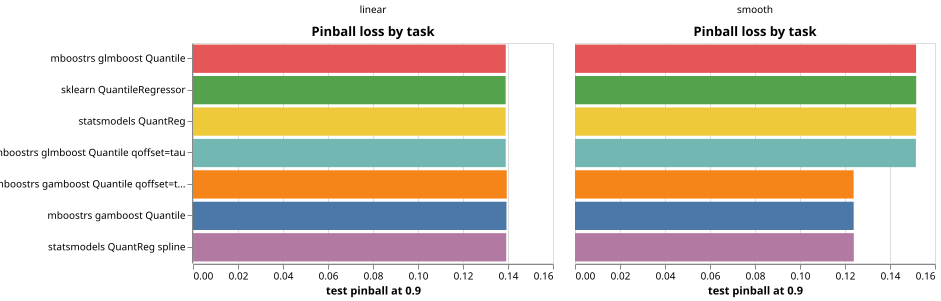

In [6]:
chart_rows = summary.filter(pl.col("method") != "generating quantile")
alt.Chart(chart_rows).mark_bar().encode(
    x=alt.X("pinball:Q", title="test pinball at 0.9", scale=alt.Scale(zero=False)),
    y=alt.Y("method:N", sort="-x", title=None),
    color=alt.Color("method:N", legend=None),
).properties(
    width=360,
    height=220,
    title="Pinball loss by task",
).facet(column=alt.Column("task:N", title=None))


## The linear quantile

`glmboost` with `Quantile(tau=0.9)` matches `QuantReg` and the unpenalised sklearn regressor. Mean pinball is {eval}`f"{value('linear', 'mboostrs glmboost Quantile', 'pinball'):.4f}"`, against {eval}`f"{value('linear', 'statsmodels QuantReg', 'pinball'):.4f}"` for statsmodels, {eval}`f"{value('linear', 'sklearn QuantileRegressor', 'pinball'):.4f}"` for sklearn, and {eval}`f"{value('linear', 'generating quantile', 'pinball'):.4f}"` for the generating quantile. Absolute error is {eval}`f"{value('linear', 'mboostrs glmboost Quantile', 'mae'):.3f}"` and {eval}`f"{value('linear', 'statsmodels QuantReg', 'mae'):.3f}"`. Starting at `qoffset=0.9` scores {eval}`f"{value('linear', 'mboostrs glmboost Quantile qoffset=tau', 'pinball'):.4f}"`. The test score does not depend on the starting offset once cross-validation chooses the step count. No path stopped at the 2,500-step cap ({eval}`f"{n_at_cap('linear', 'mboostrs glmboost Quantile')}"` for the default offset).

On seed 0 the fitted intercept is {eval}`f"{bench['recovery']['glmboost_coef']['(Intercept)']:.3f}"` against {eval}`f"{bench['recovery']['statsmodels_params']['Intercept']:.3f}"` for `QuantReg` and {eval}`f"{bench['recovery']['true_intercept']:.3f}"` for the generating quantile. `x1` is {eval}`f"{bench['recovery']['glmboost_coef']['x1']:.3f}"` against {eval}`f"{bench['recovery']['statsmodels_params']['x1']:.3f}"` and the generating slope 0.55. The boost takes about {eval}`f"{value('linear', 'mboostrs glmboost Quantile', 'seconds'):.2f}"` seconds. `QuantReg` takes about {eval}`f"{value('linear', 'statsmodels QuantReg', 'seconds'):.3f}"` seconds and did not hit its iteration limit on this seed.

A B-spline `QuantReg` on a linear quantile is slightly worse (pinball {eval}`f"{value('linear', 'statsmodels QuantReg spline', 'pinball'):.4f}"`, absolute error {eval}`f"{value('linear', 'statsmodels QuantReg spline', 'mae'):.3f}"`).


## The smooth quantile

A linear quantile misses the sine. statsmodels, sklearn and `glmboost` all score about {eval}`f"{value('smooth', 'statsmodels QuantReg', 'pinball'):.3f}"`, and the absolute error is about {eval}`f"{value('smooth', 'statsmodels QuantReg', 'mae'):.2f}"`. The generating pinball is {eval}`f"{value('smooth', 'generating quantile', 'pinball'):.4f}"`.

`gamboost` with `bbs(x1) + bols(x2) + bols(noise)` (a P-spline, a penalized cubic B-spline, in `x1` and linear terms in the other two columns) scores {eval}`f"{value('smooth', 'mboostrs gamboost Quantile', 'pinball'):.4f}"`. The B-spline `QuantReg` scores {eval}`f"{value('smooth', 'statsmodels QuantReg spline', 'pinball'):.4f}"`. Absolute error is {eval}`f"{value('smooth', 'mboostrs gamboost Quantile', 'mae'):.3f}"` against {eval}`f"{value('smooth', 'statsmodels QuantReg spline', 'mae'):.3f}"`. Passing `qoffset=0.9` scores {eval}`f"{value('smooth', 'mboostrs gamboost Quantile qoffset=tau', 'pinball'):.4f}"`. The boost takes about {eval}`f"{value('smooth', 'mboostrs gamboost Quantile', 'seconds'):.2f}"` seconds. The spline linear program fits the specified basis faster here. Boosting chooses one term at each step and can leave `noise` unused.

None of the additive paths stopped at the cap ({eval}`f"{n_at_cap('smooth', 'mboostrs gamboost Quantile')}"` for the default offset). Each step adds a shrunken, penalized fit of one term, so a term selected many times accumulates a fit whose effective smoothness penalty is much weaker than that of a single fit. mboostrs warns when this happens; the warning was issued while fitting the 2,500-step path, before cross-validation chose a shorter `mstop`, and the scored model is the cross-validated one.

## Prediction and parameter accessors

The examples below use the first linear training sample.

The starting offset is the `qoffset` quantile of the response. In mboostrs 0.1.3, which recorded these calls, `qoffset` defaulted to 0.5:

> {eval}`probe("default offset is the median, not the fitted quantile")["detail"]`

> {eval}`probe("qoffset equal to tau starts at that quantile")["detail"]`

On this seed, cross-validation then took {eval}`f"{bench['recovery']['glmboost_mstop']}"` steps from the median and {eval}`f"{bench['recovery']['glmboost_qoffset_tau_mstop']}"` steps from the 0.9 quantile, and both fits matched `QuantReg`. Starting at the target quantile shortens the path; it does not change the fit cross-validation arrives at.

`predict` defaults to `type="link"`. For `Quantile` the link is the identity, so that value is already the quantile. {eval}`probe("predict default is the quantile")["detail"]`

`logLik` refuses, and the message says why. The check loss is not a density:

> {eval}`probe("Quantile logLik")["detail"]`

`Quantile` has no nuisance parameter, and `nuisance()` returns `None`.

`tau` outside `(0, 1)` is refused: {eval}`probe("Quantile rejects tau outside (0, 1)")["error"]`, {eval}`probe("Quantile rejects tau outside (0, 1)")["detail"]`.

`autospec` with no budget names Gaussian. Its automatic family choice targets a continuous response distribution; request `Quantile` explicitly to fit a conditional quantile:

> {eval}`probe("autospec without a budget")["detail"]`

sklearn's `QuantileRegressor` defaults to `alpha=1`. The comparison uses `alpha=0`. An `alpha` of 1 shrinks the slopes and is not the check-loss fit `QuantReg` computes.

## Reproduction

The page reads `bench_quantile.json`, which stores one record per task, method and seed (four seeds, 1,500 training and 4,000 test rows, `nu=0.1`, a 2,500-step path), the seed-0 coefficients, the accessor calls, and the library versions and thread settings. Elapsed times are means over the four training seeds; each method's time covers its own fit, tuning and prediction.